# Active GLiNER: Relations between given mentions

The task: say how two mentions in a sentence are related; the mentions are given. For example, in a sentence that names *Marie Curie* and *Paris*, the pair can get the relation `physical` (she lived there).

This notebook follows the recipe from the paper:

```
your unlabelled texts
   │  1. the untrained student ranks them once, least sure first
   ▼
top N texts ──> a random quarter: human labels
           └──> the rest: LLM labels
   │  2. train the student on both (LoRA)
   ▼
a small, fast model you own ──> 3. check it on labelled dev data ──> 4. predict
```

Data: CrossRE: sentences from six domains, 17 relation types; every sentence comes with its entity mentions. The "human" labels here come from the dataset's own annotators, so you
can see the recipe end to end without labelling anything yourself.

You need a GPU (8 GB is enough) and an OpenAI-compatible LLM server. This repository
starts Gemma 4 12B with `scripts/serve_teacher_gemma.sh`; any other local or hosted
endpoint works too.

In [1]:
import json
from pathlib import Path

import torch
from IPython.display import Image, Markdown, display

from active_gliner import byod, data, tasks

TASK = "relations"
DATASET = "crossre"
TEACHER_URL = "http://127.0.0.1:8020/v1"
TEACHER_MODEL = "gemma-4-12b-qat"
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

GPU: NVIDIA GeForce RTX 3090


## 1. Your data

The tool reads JSONL files, one text per line:

+ `texts.jsonl` - unlabelled texts (`text`, and for relations the `entities` list).
+ `dev.jsonl` - a few hundred texts with correct labels, to measure accuracy.

Here we write both from the dataset.

In [2]:
demo = Path("demo-relations")
demo.mkdir(exist_ok=True)
splits = data.load(DATASET)
names = tasks.labels(DATASET, splits)  # label code -> label name


def write(path, records, with_labels):
    rows = [byod.record_to_row(r, names, with_labels) for r in records]
    path.write_text("".join(json.dumps(row, ensure_ascii=False) + "\n" for row in rows))


write(demo / "texts.jsonl", splits["pool"][:2519], with_labels=False)
write(demo / "dev.jsonl", splits["dev"][:300], with_labels=True)
labels = ",".join(names.values())
print(len(names), "labels:", labels[:200], "...")
print(open(demo / "dev.jsonl").readline()[:300])

17 labels: artifact,cause-effect,compare,general-affiliation,named,opposite,origin,part-of,physical,related-to,role,social,temporal,topic,type-of,usage,win-defeat ...
{"id": "crossre:en-US:ai-train-8", "text": "Since the early 1990s , it has been recommended by several authorities , including the Audio Engineering Society that measurements of dynamic range be made with an audio signal present , which is then filtered out in the noise floor measurement used in det


## 2. What the untrained student does

GLiNER2.5 already works for any label names, with no training. This is the score to beat.

In [3]:
task = tasks.for_dataset(DATASET)
dev = byod.read_labelled(demo / "dev.jsonl", TASK)
label_map = byod.parse_labels(labels)
student = byod.load_student(TASK, label_map)
zero_shot_f1 = task.score(dev, task.predict(student, dev, label_map), label_map)["micro"]["f1"]
print(f"Zero-shot dev F1: {100 * zero_shot_f1:.1f}")
del student
torch.cuda.empty_cache()

Zero-shot dev F1: 9.6


## 3. Rank once and split between humans and the LLM

`rank` scores every text with the untrained student, takes the 1,000 it is least sure
about (texts where it finds nothing go last), and puts a random quarter of them in
`for_humans.jsonl`. The rest goes in `for_llm.jsonl`.

From a terminal:

```bash
active-gliner rank --texts demo/texts.jsonl --task relations --labels "..." \
  --n 1000 --human-share 0.25 --out demo/rank
```

In [4]:
ranked = byod.rank(
    demo / "texts.jsonl", TASK, labels, n=1000, human_share=0.25, out_dir=demo / "rank"
)
for_humans = [json.loads(line) for line in (ranked / "for_humans.jsonl").open()]
for_llm = [json.loads(line) for line in (ranked / "for_llm.jsonl").open()]
print(len(for_humans), "texts for humans,", len(for_llm), "for the LLM")
print("example for a human:", for_humans[0]["text"][:200])

250 texts for humans, 750 for the LLM
example for a human: 4 - Goran Ivanisevic ( Croatia ) beat Scott Draper ( Australia ) 6-7 ( 1-7 ) 6-3 6-4 6-4


## 4. Human labels

In real use, people label `for_humans.jsonl` by hand, in the same format as `dev.jsonl`.
Here we copy the dataset's own labels for those texts.

In [5]:
by_id = {r.id: r for r in splits["pool"]}
write(demo / "human.jsonl", [by_id[row["id"]] for row in for_humans], with_labels=True)
print(open(demo / "human.jsonl").readline()[:300])

{"id": "crossre:en-US:news-dev-175", "text": "4 - Goran Ivanisevic ( Croatia ) beat Scott Draper ( Australia ) 6-7 ( 1-7 ) 6-3 6-4 6-4", "entities": [{"text": "Goran Ivanisevic", "start": 4, "end": 20, "label": "person"}, {"text": "Croatia", "start": 23, "end": 30, "label": "country"}, {"text": "Sco


## 5. LLM labels for the rest, then train

`fit` sends every text in `for_llm.jsonl` to the LLM (`select="all"`), checks every
answer (valid JSON, allowed labels, exact text spans), adds the human-labelled texts,
and trains a LoRA adapter. The LLM never sees the human-labelled texts.

```bash
active-gliner fit --texts demo/rank/for_llm.jsonl --select all --human demo/human.jsonl \
  --task relations --labels "..." --dev demo/dev.jsonl \
  --teacher-url http://127.0.0.1:8020/v1 --teacher-model gemma-4-12b-qat --out demo/run
```

For a hosted API, also pass `api_key_env="NAME_OF_THE_KEY_VARIABLE"`.

In [6]:
run = byod.fit(
    texts=ranked / "for_llm.jsonl",
    task=TASK,
    labels=labels,
    teacher_url=TEACHER_URL,
    teacher_model=TEACHER_MODEL,
    select="all",
    human=demo / "human.jsonl",
    dev=demo / "dev.jsonl",
    out_dir=demo / "run",
)
print(run)

demo-relations/run


## 6. Check the result

Every run folder holds plain files: a one-page report, training curves, every LLM label
and every wrong prediction.

In [7]:
metrics = json.loads((run / "metrics.json").read_text())
trained_f1 = metrics["dev"]["micro"]["f1"]
print(f"Dev F1: zero-shot {100 * zero_shot_f1:.1f} -> trained {100 * trained_f1:.1f}")
print("LLM answers:", json.loads((run / "teacher_stats.json").read_text()))

Dev F1: zero-shot 9.6 -> trained 21.4
LLM answers: {'elapsed_s': 0.30140728293918073, 'workers': 8, 'gpu_shared': False, 'requests': 0, 'cache_hits': 750, 'retries': 0, 'duplicate': 0, 'prompt_tokens': 0, 'completion_tokens': 0, 'latency_s_total': 0.0, 'errors_by_kind': {'json': 81}, 'invalid_records': 81, 'valid_rate': 0.892, 'cost_usd': 0.0}


In [8]:
display(Markdown((run / "report.md").read_text()))

# user: all, N=750, seed=1

Locale: en-US. Labels: custom. LoRA r=16, alpha=32.0, task LR=0.0009433746945314401. Augmentation: False.
Acquisition threshold: 0.5. Evaluation threshold: 0.5.

| Split | Micro F1 | Macro F1 |
| --- | ---: | ---: |
| dev | 0.2136 | 0.1923 |

Best step: 1000. Stop reason: max_steps.
Wall time: 888.49 s. Training time: 854.61 s.

| Type | Precision | Recall | F1 | Support |
| --- | ---: | ---: | ---: | ---: |
| artifact | 0.6098 | 0.3165 | 0.4167 | 79 |
| cause-effect | 0.2000 | 0.1667 | 0.1818 | 6 |
| compare | 0.1613 | 0.5263 | 0.2469 | 19 |
| general-affiliation | 0.1049 | 0.2000 | 0.1376 | 75 |
| named | 0.1848 | 0.2000 | 0.1921 | 85 |
| opposite | 0.0000 | 0.0000 | 0.0000 | 32 |
| origin | 0.0000 | 0.0000 | 0.0000 | 48 |
| part-of | 0.2981 | 0.2981 | 0.2981 | 104 |
| physical | 0.2500 | 0.1377 | 0.1776 | 167 |
| related-to | 0.0568 | 0.2368 | 0.0916 | 76 |
| role | 0.5833 | 0.2014 | 0.2995 | 278 |
| social | 0.3333 | 0.3333 | 0.3333 | 3 |
| temporal | 0.0744 | 0.1452 | 0.0984 | 62 |
| topic | 0.0000 | 0.0000 | 0.0000 | 9 |
| type-of | 0.0286 | 0.0233 | 0.0256 | 43 |
| usage | 0.0556 | 0.1667 | 0.0833 | 12 |
| win-defeat | 0.6250 | 0.7627 | 0.6870 | 59 |

[Training curves](plots/training_curves.png) · [Calibration](plots/calibration.png) · [Errors](errors.jsonl)

Extraction calibration includes emitted predictions only; low bins can be empty because of the evaluation threshold. Classification includes all label probabilities.


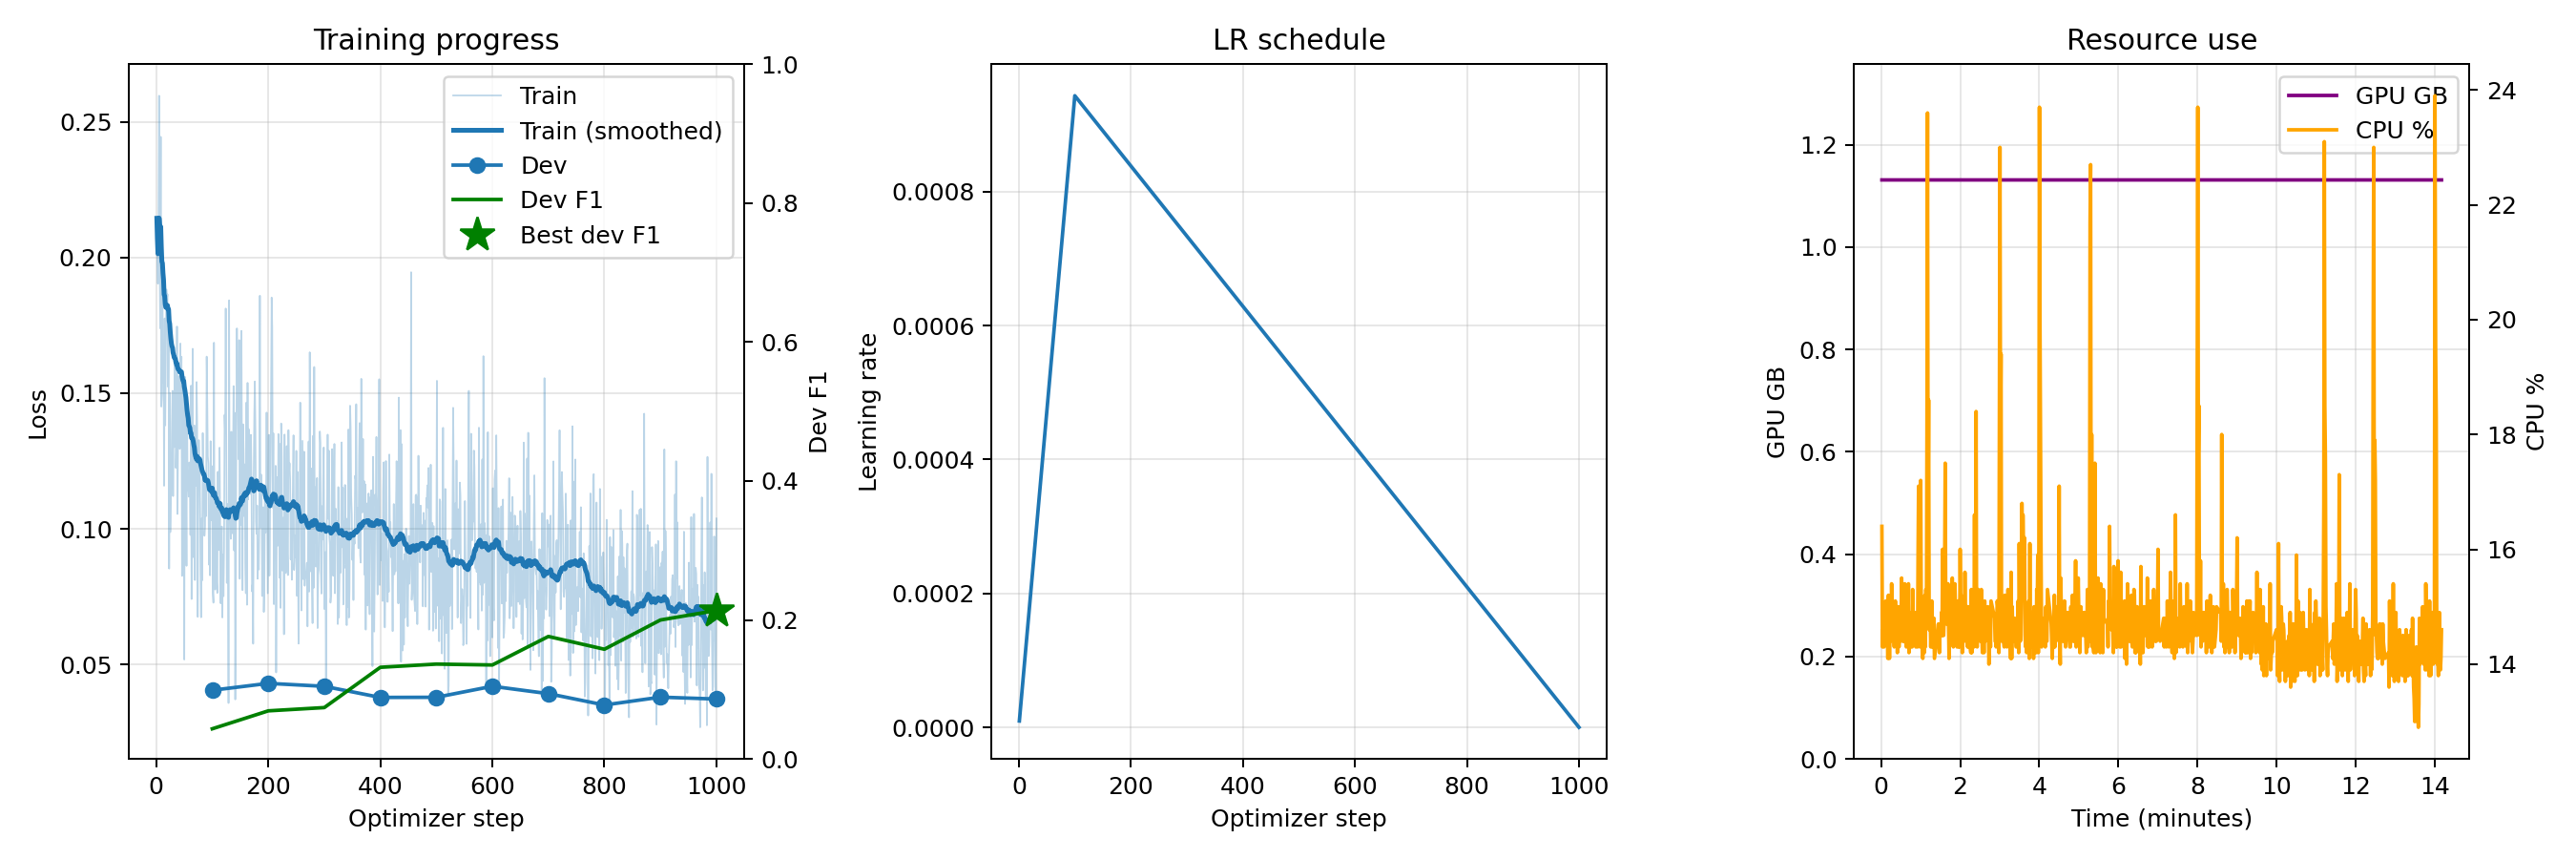

In [9]:
display(Image(filename=str(run / "plots" / "training_curves.png")))

## 7. Use the trained model

`predict` loads the adapter and runs on a GPU or a CPU:

```bash
active-gliner predict --adapter demo/run/adapter/best --task relations --labels "..." \
  --texts new.jsonl
```

In [10]:
rows = [json.loads(line) for line in open(demo / "dev.jsonl")][:3]
inputs = [{"text": r["text"], "entities": r["entities"]} for r in rows]
(demo / "new.jsonl").write_text("".join(json.dumps(r) + "\n" for r in inputs))
predictions = byod.predict(run / "adapter" / "best", TASK, labels, demo / "new.jsonl")
for row, prediction in zip(rows, predictions, strict=True):
    print(row["text"][:150])
    mention = [e["text"] for e in row["entities"]]
    print("   ", [(mention[r["head"]], r["type"], mention[r["tail"]]) for r in prediction["relations"]])

Since the early 1990s , it has been recommended by several authorities , including the Audio Engineering Society that measurements of dynamic range be
    [('Audio Engineering Society', 'related-to', 'audio signal')]
Sigmoid function Cross entropy loss is used for predicting K independent probability values in math 0,1 / math .
    []
The inclusion of a C + + interpreter ( CINT until version 5.34 , Cling from version 6 ) makes this package very versatile as it can be used in interac
    [('C + +', 'related-to', 'MATLAB'), ('C + +', 'usage', 'MATLAB'), ('CINT', 'named', 'Cling'), ('Cling', 'named', 'CINT')]


## What the paper found for this task

Relations are hard for both the LLM and the student (F1 below 50). LLM labels cost more here than on NER: 2 to 3 points for a quarter of LLM labels.

See the paper (`paper/main.pdf`, Section 4.4) for the numbers on every dataset.